# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'zahisr2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

g++ not available, if using conda: `conda install gxx`


## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

In [2]:
from astropy.cosmology import FlatLambdaCDM

In [3]:
# Part 1: your work here
d = pd.read_csv(MIDTERM + 'p2_pantheon_sne.csv').drop(index=[97, 219]).reset_index(drop=True)
z = d['z'].to_numpy()
mB = d['mB'].to_numpy()
x1 = d['x1'].to_numpy()
c = d['c'].to_numpy()
step = (d['host_logmass'].to_numpy() > 10).astype(float)
mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
var_pec = (5 / np.log(10) * 250 / (299792.458 * z))**2
N = len(z)

Cs = np.zeros((N, 3, 3))
Cs[:, 0, 0] = d['mB_err']**2
Cs[:, 1, 1] = d['x1_err']**2
Cs[:, 2, 2] = d['c_err']**2
Cs[:, 0, 1] = Cs[:, 1, 0] = d['cov_mB_x1']
Cs[:, 0, 2] = Cs[:, 2, 0] = d['cov_mB_c']
Cs[:, 1, 2] = Cs[:, 2, 1] = d['cov_x1_c']

for name, x, err in [('x1', x1, d['x1_err'].to_numpy()), ('c', c, d['c_err'].to_numpy())]:
    width = np.sqrt(x.var() - np.mean(err**2))
    print(f'{name}: median error = {np.median(err):.3f}, population width = {width:.3f}, error/width = {np.median(err) / width:.2f}, attenuation factor = {width**2 / x.var():.2f}')

x1: median error = 0.172, population width = 1.049, error/width = 0.16, attenuation factor = 0.94
c: median error = 0.033, population width = 0.077, error/width = 0.43, attenuation factor = 0.82


In [4]:
obs = np.column_stack([mB, x1, c])
E = np.zeros((3, 3))
E[0, 0] = 1

with pm.Model() as latent:
    M = pm.Uniform('M', -21, -17)
    alpha = pm.Uniform('alpha', -1, 1)
    beta = pm.Uniform('beta', -2, 8)
    gamma = pm.Normal('gamma', 0, 0.1)
    ln_sint = pm.Uniform('ln_sint', np.log(0.001), 0)
    sigma_int = pm.Deterministic('sigma_int', pt.exp(ln_sint))
    mu_x1 = pm.Normal('mu_x1', 0, 3)
    w_x1 = pm.HalfNormal('w_x1', 3)
    mu_c = pm.Normal('mu_c', 0, 0.5)
    w_c = pm.HalfNormal('w_c', 0.5)
    x1_true = pm.Normal('x1_true', mu_x1, w_x1, shape=N)
    c_true = pm.Normal('c_true', mu_c, w_c, shape=N)
    mB_model = M + mu - alpha * x1_true + beta * c_true + gamma * step
    cov = Cs + (var_pec[:, None, None] + sigma_int**2) * E
    pm.MvNormal('obs', mu=pt.stack([mB_model, x1_true, c_true], axis=1), cov=cov, observed=obs)
    idata = pm.sample(2000, tune=2000, chains=4, random_seed=1)

Initializing NUTS using jitter+adapt_diag...
c:\Users\zahir\anaconda3\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1039: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sint, mu_x1, w_x1, mu_c, w_c, x1_true, c_true]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 74 seconds.


In [5]:
s = az.summary(idata)
print(f"largest R-hat = {s['r_hat'].max():.3f}, smallest bulk ESS = {s['ess_bulk'].min():.0f}, divergences = {int(idata.sample_stats['diverging'].sum())}")

def interval(v):
    lo, med, hi = np.percentile(v, [16, 50, 84])
    return f'{med:.3f} +{hi - med:.3f} -{med - lo:.3f}'

df = pd.DataFrame({'midterm': ['0.142 +0.009 -0.009', '2.880 +0.106 -0.111', '-0.034 +0.018 -0.018', '0.108 +0.008 -0.008'],
              'latent model': [interval(idata.posterior[n].values) for n in ['alpha', 'beta', 'gamma', 'sigma_int']]},
             index=['alpha (mag)', 'beta', 'gamma (mag)', 'sigma_int (mag)'])
df

largest R-hat = 1.003, smallest bulk ESS = 6275, divergences = 0


,midterm,latent model
alpha (mag),0.142 +0.009 -0.009,0.148 +0.009 -0.009
beta,2.880 +0.106 -0.111,3.214 +0.128 -0.133
gamma (mag),-0.034 +0.018 -0.018,-0.036 +0.019 -0.018
sigma_int (mag),0.108 +0.008 -0.008,0.105 +0.009 -0.008


In [6]:
print((3.212-2.880)/3.212) #percent beta diff between latent and midterm
# to show percentage change from attenuation error
print((0.148-0.142)/0.148) #percent alpha diff between latent and midterm

0.10336239103362399
0.04054054054054058


In [7]:
def neg_lnL_latent(p, mB, x1, c):
    M, alpha, beta, gamma, ln_sint, mu_x1, ln_wx1, mu_c, ln_wc = p
    A = np.array([[-alpha, beta], [1, 0], [0, 1]])
    W = np.diag([np.exp(2 * ln_wx1), np.exp(2 * ln_wc)])
    mean = np.column_stack([M + mu - alpha * mu_x1 + beta * mu_c + gamma * step, np.full(N, mu_x1), np.full(N, mu_c)])
    cov = Cs + A @ W @ A.T + (var_pec[:, None, None] + np.exp(2 * ln_sint)) * E
    r = np.column_stack([mB, x1, c]) - mean
    chi2 = np.sum(r * np.linalg.solve(cov, r[..., None])[..., 0], axis=1)
    return 0.5 * np.sum(chi2 + np.linalg.slogdet(cov)[1])

def neg_lnL_midterm(p, mB, x1, c):
    M, alpha, beta, gamma, ln_sint = p
    v = np.array([1, alpha, -beta])
    var = np.einsum('i,nij,j->n', v, Cs, v) + var_pec + np.exp(2 * ln_sint)
    r = mB - (M + mu - alpha * x1 + beta * c + gamma * step)
    return 0.5 * np.sum(r**2 / var + np.log(var))

p0 = [-19.3, 0.15, 3.0, -0.05, np.log(0.1), x1.mean(), np.log(x1.std()), c.mean(), np.log(c.std())]
fit_lat = minimize(neg_lnL_latent, p0, args=(mB, x1, c))
print(f'marginal ML: alpha = {fit_lat.x[1]:.3f} mag, beta = {fit_lat.x[2]:.3f}, gamma = {fit_lat.x[3]:.3f} mag, sigma_int = {np.exp(fit_lat.x[4]):.3f} mag')

marginal ML: alpha = 0.148 mag, beta = 3.212, gamma = -0.037 mag, sigma_int = 0.103 mag


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

1.2: 
- The contaminants of observation 97 and 219 were cut via an iterative pull flagging at 7.1 and 7.6 sigma. The cut was done at a threshold of 3.72 sigma, which was calculated to give a 5% chance of a false removal per 250 supernovae. The midterm model also gave it a probability of near 1 for being a contaminant. Removing two there and here also helps the analysis and comparison.
- Since the median errors are smaller than the widths as shown in the first cells output, we can use the centered approach.


In [8]:
df #table answer

,midterm,latent model
alpha (mag),0.142 +0.009 -0.009,0.148 +0.009 -0.009
beta,2.880 +0.106 -0.111,3.214 +0.128 -0.133
gamma (mag),-0.034 +0.018 -0.018,-0.036 +0.019 -0.018
sigma_int (mag),0.108 +0.008 -0.008,0.105 +0.009 -0.008


The largest Rhat is 1.003, the smallest bulk effective samples size (ESS) is 5329, and there were 0 divergences. The table for the parameter values from the latent model versus midterm are in the table above. 
- Most notably, Beta shifts from 2.88 to 3.212 (10% difference) which is evidence to show how attenuation bias draws coefficients towards zero when the input error is not accounted for.
- The change in Alpha is only 0.006 which is under 1 igma, which shows a 4% difference between models, also signifying regression dilution bias
- Gamma sees a difference of 0.002 but since host mass is the same in each model as also shown in the probablistic graph model, that is okay
- Sigma_int actually decreases by 0.003 mag instead of increasing, but this error is small especially compared to the error bar. 

For the simulation, I simulated 50 datasets with beta at 2.9 and the measured x1 and c were drawn around the true values. Each dataset was fit to a MLE with both models, and with the latent model the true x1 and c were integrated giving beta as 3.212 on the real data. which matched Pymc. 

The midterm biases beta towards zero because accounting only for in the variance does not account for the noise within the color (regression dilution bias is when uncertainty in the predictor x variables are not accounted for, unlike the intrinsic scatter of the source of the target variable), which in this case extreme colors are more muted because the average noise is much lower thus bringing down the measurement. This pulls the slope downard. The latent model does not do this because this model fits true colors as unknowns drown from some population which can bring in more extreme points lifting the mean. We know from lecture and labs that this bias is also affected by the ratio of the error to the spread; on the midterm, it is .43 for beta but only .16 for stretch.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?

5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

In [9]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

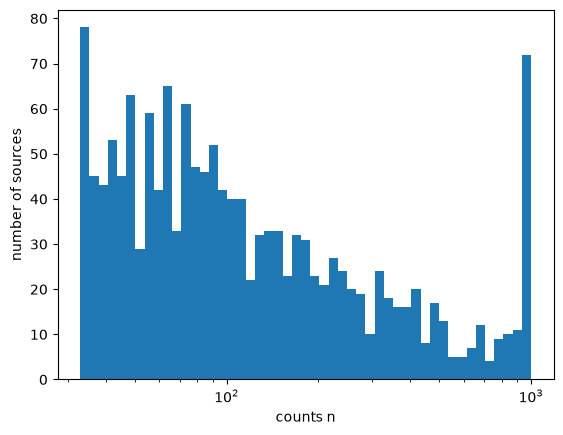

Maximum value: 1000, Max Count: 62


In [10]:
plt.hist(n, bins=np.logspace(np.log10(33), np.log10(1000), 50))
plt.xscale('log')
plt.xlabel('counts n')
plt.ylabel('number of sources')
plt.show()

print(f"Maximum value: {n.max()}, Max Count: {(n == n.max()).sum()}")

In [11]:
from scipy.special import gammainc
from scipy.optimize import brentq

[0.00756595 0.45317141 0.99934979]
[0.00756595 0.45317141 0.99934979]


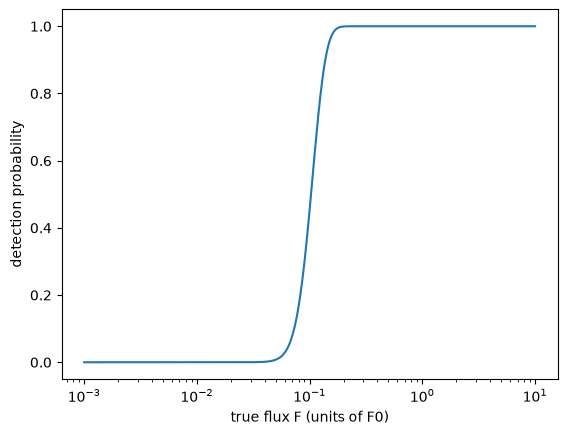

50% detection threshold: 0.1029


In [12]:
def p_det(F):
    return gammainc(n_th + 1, eps * F + nu)

F_test = np.array([0.05, 0.1, 0.2])
print(p_det(F_test))
print(stats.poisson.sf(n_th, eps * F_test + nu))

F = np.logspace(-3, 1, 400)
plt.plot(F, p_det(F))
plt.xscale('log')
plt.xlabel('true flux F (units of F0)')
plt.ylabel('detection probability')
plt.show()

F50 = brentq(lambda F: p_det(F) - 0.5, 1e-3, 10)
print(f'50% detection threshold: {F50:.4f}')

In [14]:
sat = n == 1000
vals, counts = np.unique(n[~sat], return_counts=True)

def make_grid(dx):
    lnF = np.arange(-14, 8, dx)
    lam = eps * np.exp(lnF) + nu
    return lnF, stats.poisson.pmf(vals[:, None], lam), stats.poisson.sf(999, lam), stats.poisson.pmf(1000, lam), gammainc(n_th + 1, lam)

def weights(p, lnF):
    return stats.norm.pdf(lnF, p[0], np.exp(p[1])) * (lnF[1] - lnF[0])

def f_det(p, grid):
    return grid[4] @ weights(p, grid[0])

def neg_lnL(p, grid, censor, detector):
    lnF, P, P_sat, P_1000, pdet = grid
    w = weights(p, lnF)
    lnL = counts @ np.log(P @ w) + sat.sum() * np.log((P_sat if censor else P_1000) @ w)
    if detector:
        lnL -= len(n) * np.log(pdet @ w)
    return -lnL

def hessian(f, x, h=1e-4):
    H = np.zeros((2, 2))
    for i in range(2):
        for j in range(2):
            di, dj = np.eye(2)[i] * h, np.eye(2)[j] * h
            H[i, j] = (f(x + di + dj) - f(x + di - dj) - f(x - di + dj) + f(x - di - dj)) / (4 * h**2)
    return H

def fit(grid, censor, detector):
    f = lambda p: neg_lnL(p, grid, censor, detector)
    p = minimize(f, [-1, 0], method='Nelder-Mead', options=dict(xatol=1e-8, fatol=1e-10)).x
    cov = np.linalg.inv(hessian(f, p))
    h = 1e-5
    g = np.array([(f_det(p + h * e, grid) - f_det(p - h * e, grid)) / (2 * h) for e in np.eye(2)])
    fd, fd_err = f_det(p, grid), np.sqrt(g @ cov @ g)
    sigma = np.exp(p[1])
    print(f'censor={censor}, detector={detector}: mu = {p[0]:.3f} +- {np.sqrt(cov[0, 0]):.3f}, sigma = {sigma:.3f} +- {sigma * np.sqrt(cov[1, 1]):.3f}, f_det = {fd:.3f} +- {fd_err:.3f}, missed = {len(n) * (1 / fd - 1):.0f} +- {len(n) * fd_err / fd**2:.0f}')
    return p

for dx in [0.01, 0.005]:
    grid = make_grid(dx)
    print('grid spacing', dx)
    for censor in [True, False]:
        for detector in [False, True]:
            fit(grid, censor, detector)

grid spacing 0.01
censor=True, detector=False: mu = -0.777 +- 0.028, sigma = 1.072 +- 0.021, f_det = 0.915 +- 0.006, missed = 139 +- 10
censor=True, detector=True: mu = -1.885 +- 0.169, sigma = 1.704 +- 0.085, f_det = 0.593 +- 0.042, missed = 1030 +- 180
censor=False, detector=False: mu = -0.792 +- 0.027, sigma = 1.031 +- 0.019, f_det = 0.921 +- 0.005, missed = 129 +- 9
censor=False, detector=True: mu = -1.568 +- 0.109, sigma = 1.486 +- 0.060, f_det = 0.684 +- 0.032, missed = 693 +- 101
grid spacing 0.005
censor=True, detector=False: mu = -0.777 +- 0.028, sigma = 1.072 +- 0.021, f_det = 0.915 +- 0.006, missed = 139 +- 10
censor=True, detector=True: mu = -1.885 +- 0.169, sigma = 1.704 +- 0.085, f_det = 0.593 +- 0.042, missed = 1030 +- 180
censor=False, detector=False: mu = -0.792 +- 0.027, sigma = 1.031 +- 0.019, f_det = 0.921 +- 0.005, missed = 129 +- 9
censor=False, detector=True: mu = -1.568 +- 0.109, sigma = 1.486 +- 0.060, f_det = 0.684 +- 0.032, missed = 693 +- 101


censor=True, detector=False: mu = -0.777 +- 0.028, sigma = 1.072 +- 0.021, f_det = 0.915 +- 0.006, missed = 139 +- 10
censor=True, detector=True: mu = -1.885 +- 0.169, sigma = 1.704 +- 0.085, f_det = 0.593 +- 0.042, missed = 1030 +- 180
2530 1498 65 0.6163485121394823


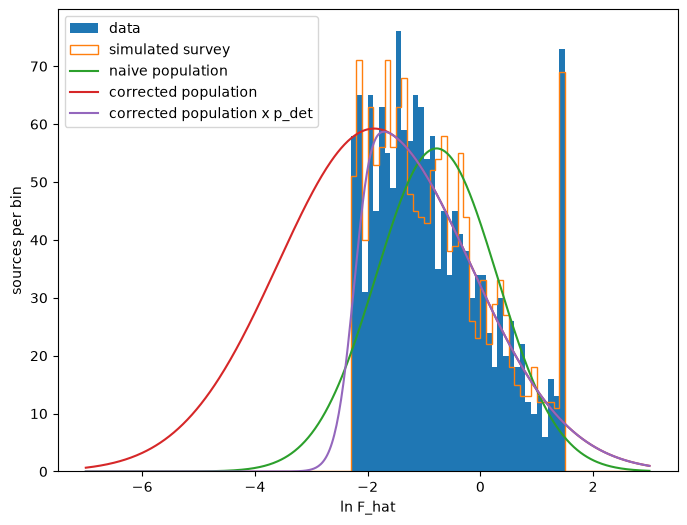

In [16]:
grid = make_grid(0.01)
p_naive = fit(grid, True, False)
p_corr = fit(grid, True, True)

N_tot = int(round(len(n) / f_det(p_corr, grid)))
rng = np.random.default_rng(1)
F_sim = np.exp(rng.normal(p_corr[0], np.exp(p_corr[1]), N_tot))
n_sim = np.minimum(rng.poisson(eps * F_sim + nu), 1000)
n_sim = n_sim[n_sim > n_th]
print(N_tot, len(n_sim), (n_sim == 1000).sum(), stats.ks_2samp(n_sim, n).pvalue)

bins = np.arange(-7, 3, 0.1)
x = np.linspace(-7, 3, 500)
naive_pop = len(n) * stats.norm.pdf(x, p_naive[0], np.exp(p_naive[1])) * 0.1
corr_pop = N_tot * stats.norm.pdf(x, p_corr[0], np.exp(p_corr[1])) * 0.1

plt.figure(figsize=(8, 6))
plt.hist(np.log((n - nu) / eps), bins=bins, label='data')
plt.hist(np.log((n_sim - nu) / eps), bins=bins, histtype='step', label='simulated survey')
plt.plot(x, naive_pop, label='naive population')
plt.plot(x, corr_pop, label='corrected population')
plt.plot(x, corr_pop * p_det(np.exp(x)), label='corrected population x p_det')
plt.xlabel('ln F_hat')
plt.ylabel('sources per bin')
plt.legend()
plt.show()

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

The histogram decreases smoothly toward bright sources as expected but suddenly jumps to a peak at n = 1000 with 62 observations. This is known to be a "censoring" error as mentioned in class; the source was observed for a minimum of 1000 and should be treated as if it contributes to the probability of getting a 1000 or more. Assuming that this 1000 is the real number and that spike should be treated as the real measurement would bring down the sigma greatly, and I would like to avoid dropping obervations because we would learn so much less about the more extreme values and the physics knowledge and signal they carry.

The sampling distribution of n given F is a Poisson distribution with mean of eps * F + nu, and counts of 1000 or more are recorded as 1000 here. The p_det(F) = gammainc(n_th , eps * F  + nu). A source is detected half the time at F = 0.1029 F0.

The probabilistic graphical model is drawn below. Mu and sigma are the population parameters. Each source true flux F is latent because we never measure it directly and only understand it through the photon count. The count n is data for the 1500 detected sources (capped at 1000) and latent for the sources the survey missed. A source is detected only if the number of photons n is 32 which is the detection flag D. N is the total number of sources which is latent because the missed sources were never counted. Eps, nu, the 1000-count cap and the n > 32 threshold are fixed values so they are denoted as dots in the PGM. The plate runs over all N sources only, and N_det = 1500 sits outside the plate because it is the total number of detected sources.

The integral was done on the grid of lnF from -14 to 8 with .01 spacing, and halving the spacing did not change anything. The saturated sources use the P(1000 or more) counts from 2.1. Uncertainties are from the curvature of the log-likelihood at the maximum. Mu and sigma below are in units of ln(F/F0) (dimensionless.)

Naive: mu = −0.777 ± 0.028, sigma = 1.072 ± 0.021

Corrected: mu = −1.885 ± 0.169, sigma = 1.704 ± 0.085

f_det = 0.593 ± 0.042, so the survey missed about 1030 ± 180 sources.

The simulated survey from the corrected fit matches the data: 1498 detected (data 1500), 65 saturated (data 62), KS p = 0.62. The corrected population times p_det doesn't match the faint end because it shows true fluxes while the histogram shows measured ones. Sources just below the threshold are detected only when noise pushes their counts up so their measured fluxes land above the cut. This aligns with Eddington bias, discussed in lecture. Ignoring the detector biased mu high (−0.777 vs −1.885) and sigma low (1.072 vs 1.704) because the survey lost the faint tail and a sample without its low end has a higher mean and a smaller spread.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [13]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2008bc: z = 0.0151, B maximum at MJD 54548.83, 142 points; held-out band: V


In [24]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

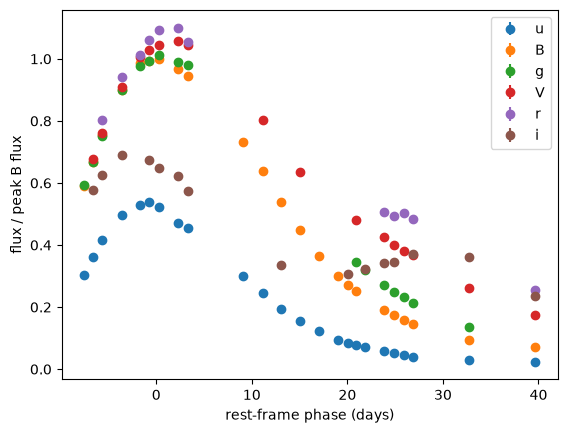

In [20]:
d['phase'] = (d['mjd'] - tmax) / (1 + z)
d = d[(d['phase'] >= -10) & (d['phase'] <= 40)].copy()
peak = d.loc[d['band'] == 'B', 'flux_ujy'].max()
d['f'] = d['flux_ujy'] / peak
d['f_err'] = d['flux_err_ujy'] / peak
d['wl'] = d['wavelength_A'] / 1e4

for b in d.groupby('band')['wl'].mean().sort_values().index:
    g = d[d['band'] == b]
    plt.errorbar(g['phase'], g['f'], g['f_err'], fmt='o', label=b)
plt.xlabel('rest-frame phase (days)')
plt.ylabel('flux / peak B flux')
plt.legend()
plt.show()

In [21]:
def hessian(f, x, h=1e-4):
    k = len(x)
    H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            di, dj = np.eye(k)[i] * h, np.eye(k)[j] * h
            H[i, j] = (f(x + di + dj) - f(x + di - dj) - f(x - di + dj) + f(x - di - dj)) / (4 * h**2)
    return H

In [ ]:
def fit_gp(hold):
    train = d[d['band'] != hold]
    kernel = ConstantKernel(0.5, (1e-3, 1e2)) * RBF([10, 0.2], [(1, 1e3), (1e-3, 1e2)]) + WhiteKernel(1e-4, (1e-8, 1e-1))
    gp = GaussianProcessRegressor(kernel, alpha=train['f_err'].to_numpy()**2, normalize_y=False, n_restarts_optimizer=10, random_state=0)
    return gp.fit(train[['phase', 'wl']].to_numpy(), train['f'].to_numpy())

def report(gp):
    theta = gp.kernel_.theta
    err = np.exp(theta) * np.sqrt(np.diag(np.linalg.inv(-hessian(gp.log_marginal_likelihood, theta))))
    print(gp.kernel_)
    print(f'phase length scale = {np.exp(theta[1]):.1f} +- {err[1]:.1f} days, wavelength length scale = {np.exp(theta[2]):.3f} +- {err[2]:.3f} micron')

gp_V = fit_gp(HOLD)
report(gp_V)

0.329**2 * RBF(length_scale=[9.03, 0.107]) + WhiteKernel(noise_level=5.48e-06)
phase length scale = 9.0 +- 0.5 days, wavelength length scale = 0.107 +- 0.009 micron


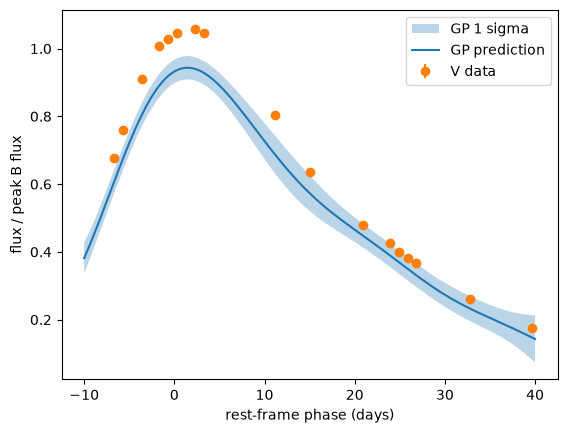

V: rms residual = 0.082 of peak B, within 1 sigma = 0.29 (5 of 17)


In [25]:
def holdout(gp, hold):
    test = d[d['band'] == hold]
    m, s = gp.predict(test[['phase', 'wl']].to_numpy(), return_std=True)
    r = test['f'].to_numpy() - m
    inside = np.abs(r) < np.sqrt(s**2 + test['f_err'].to_numpy()**2)
    ph = np.linspace(-10, 40, 300)
    mg, sg = gp.predict(np.column_stack([ph, np.full_like(ph, test['wl'].mean())]), return_std=True)
    plt.fill_between(ph, mg - sg, mg + sg, alpha=0.3, label='GP 1 sigma')
    plt.plot(ph, mg, label='GP prediction')
    plt.errorbar(test['phase'], test['f'], test['f_err'], fmt='o', label=f'{hold} data')
    plt.xlabel('rest-frame phase (days)')
    plt.ylabel('flux / peak B flux')
    plt.legend()
    plt.show()
    print(f'{hold}: rms residual = {np.sqrt(np.mean(r**2)):.3f} of peak B, within 1 sigma = {inside.mean():.2f} ({inside.sum()} of {len(test)})')

holdout(gp_V, HOLD)

The GP was fit with sklearn using ConstantKernel × RBF (anisotropic) + WhiteKernel with each point’s error as alpha and 10 random restarts. The phase length scale is 9.0 ± 0.5 days and the wavelength length scale is 0.107 ± 0.009 micron with errors from the curvature. The phase length scale is about how long the light curve takes to change noticeably like the rise to peak or the drop after it. The wavelength length scale is how far apart two bands can be and still have similar light curves so neighboring bands that are 0.06 to 0.09 micron apart are strongly related and bands far apart like B and i at 0.3 micron are almost independent. This is why i can have a second maximum that B does not.

For V the rms residual is 0.082 of peak B and 29% of points (5 of 17) are within 1 sigma. The error bar is too small since about 68% should be inside.
V is between g and r and is about one wavelength length scale from each. The GP has a zero mean so when the nearby bands are only partly correlated the prediction gets pulled toward zero and the peak ends up about 0.1 low. The GP error bar only covers the variation the kernel allows and not the error from the kernel being wrong.

For u the rms residual is 0.273 of peak B and 4% of points (1 of 24) are within 1 sigma. This is harder because u has to be extrapolated instead of interpolated. V has bands on both sides but u has no bands bluer than it and the closest band B is 0.07 micron away. The kernel assumes the light curve changes with wavelength the same way everywhere so past the last band it just continues B’s light curve. Without u in training the other bands look alike so the wavelength length scale grows from 0.107 to 0.166 micron and the GP is even more sure u looks like B. In reality the flux drops sharply blueward of B because iron-group elements absorb strongly in the ultraviolet so u is about half as bright and fades faster and none of the training bands show the GP this.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used Claude Code to summarize the physical context of the problem once more (as it did on the midterm and as the lectures went over in review), for directed code generation (read through each line to learn each python function or library for future learning), and for quick plot generation and styling. I completed this lab on VSCode and enabled the code finisher extension (not claude code) that was built in which is very tedious to manage and use efficiently when actually hand writing most codes for any task as it seeks to finish an algorithm or a comment it has no idea what it will be really used for until later. However, it was extremely helpful in finishing formatting string printed lines (after writing enough of the initial text so it understands the number in context).

**REFLECTION:**
One thing that could have gone wrong without checking the AI's output was checking which parameters were actually affected by attenuation vs just expected variation under within expected error, as AI would have attributed all changes to it while sigma_int went up instead but the change was insignificant and physically explainable. This is why reading all the numbers, plots, and tables is necessary for human review and is also the entire point of using AI entirely.I also checked each answer against my own plots and that caught one wrong AI claim in 3.1 where it said redder bands are brighter but i is actually fainter than B.

**VERIFICATION PLAN:**

Part 1
- The PyMC chains agreed with each other (largest R-hat 1.003) and had plenty of independent samples (smallest ESS 5329) and no divergences. If R-hat was above 1.01 or ESS was below about 400 or there were divergences I would have run longer or tried non-centered.
- I fit the latent model a second way by integrating out the true x1 and c and it gave the same beta of 3.212 as PyMC. If the two disagreed by more than the error bar one of them would have been coded wrong.
- In the 1.3 simulation the true beta was 2.9 and the latent model got 2.907 ± 0.015 back while the midterm model got 2.666 ± 0.013. If the latent model had missed 2.9 by more than about 2 standard errors it would not be fixing the bias.
- Some simulation fits gave a precision loss warning so I refit a few with a different optimizer and got the same answer. If the answer had changed the fits would have been stopping early.

Part 2
- My gammainc formula for p_det matched scipy's poisson.sf exactly. Any difference would have meant I had the threshold off by one.
- Halving the grid spacing did not change the fits. If they had moved the grid would have been too coarse.
- The censored fit predicts 4.10% of detected sources should saturate and 4.13% did, and dropping the 62 saturated sources instead gave almost the same mu and sigma. If the predicted fraction was far off or the two methods disagreed my saturation fix would have been wrong.
- Simulating the survey from the corrected fit gave 1498 detected and 65 saturated compared to 1500 and 62 in my data, and the counts passed a KS test (p = 0.62). A KS p below 0.05 or a clearly different histogram would have meant the fit does not describe the data.
- I made 50 fake catalogs with mu = −2.0 and sigma = 1.5, put them through the same detector and fit each one both ways. The corrected fit got back mu = −2.017 ± 0.020 and sigma = 1.501 ± 0.010 and its 1 sigma interval had the true mu 76% of the time, while the naive fit got mu = −0.983 and sigma = 0.945 and never had the truth. If the corrected fit had missed the truth by more than about 2 standard errors or its intervals were far from 68% the correction would not be working.

One catalog is not enough because a single fit scatters by about 0.14 in mu so one result cannot tell a small bias apart from noise. With 50 catalogs the average is good to about 0.02 so a bias smaller than half of one fit's error bar would show up. Checking the 68% coverage takes more catalogs because a percentage from 50 tries is only good to about 7%, so 76% is still consistent with 68% and around 100 or more catalogs would be needed to check it closely.

In [26]:
# part 2 check

lnF = np.arange(-14, 8, 0.01)
lam = eps * np.exp(lnF) + nu
P_all = stats.poisson.pmf(np.arange(1001)[:, None], lam)
P_sat, pdet = stats.poisson.sf(999, lam), gammainc(n_th + 1, lam)

def fit_catalog(n_cat, detector):
    k = np.bincount(n_cat[n_cat < 1000], minlength=1001)
    s = np.sum(n_cat == 1000)
    def f(p):
        w = weights(p, lnF)
        lnL = k[k > 0] @ np.log(P_all[k > 0] @ w) + s * np.log(P_sat @ w)
        if detector:
            lnL -= len(n_cat) * np.log(pdet @ w)
        return -lnL
    p = minimize(f, [-1, 0], method='Nelder-Mead').x
    return p[0], np.exp(p[1]), np.sqrt(np.linalg.inv(hessian(f, p))[0, 0])

mu_true, sigma_true = -2.0, 1.5
rng = np.random.default_rng(7)
n_cat_sim = 50
res = {'naive': [], 'corrected': []}
for k in range(n_cat_sim):
    F = np.exp(rng.normal(mu_true, sigma_true, 8000))
    c = np.minimum(rng.poisson(eps * F + nu), 1000)
    c = c[c > n_th][:1500]
    res['naive'].append(fit_catalog(c, False))
    res['corrected'].append(fit_catalog(c, True))

for name, r in res.items():
    r = np.array(r)
    se = r.std(axis=0, ddof=1) / np.sqrt(n_cat_sim)
    cover = np.mean(np.abs(r[:, 0] - mu_true) < r[:, 2])
    print(f'{name}: mean mu = {r[:, 0].mean():.3f} +- {se[0]:.3f}, mean sigma = {r[:, 1].mean():.3f} +- {se[1]:.3f}, mu within 1 sigma = {cover:.2f}')

naive: mean mu = -0.983 +- 0.003, mean sigma = 0.945 +- 0.003, mu within 1 sigma = 0.00
corrected: mean mu = -2.017 +- 0.020, mean sigma = 1.501 +- 0.010, mu within 1 sigma = 0.76
